# Antarctic contribution to sea level

Use IMBIE 2018, Rignot et al. 2019 and Shepherd et al. 2019 to compute Antarctic contribution to sea level



In [218]:
import sys
sys.path.append('../code')
import importlib

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import SeaLevelContrib as slc

In [254]:
# Makes clearer plots on retina display
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

In [208]:
importlib.reload(slc)

<module 'SeaLevelContrib' from '/Users/dewilebars/Projects/SLBudget/notebooks/../code/SeaLevelContrib.py'>

## IMBIE 2018

In [189]:
im18_df = slc.ant_imbie(2018)
im18_df = im18_df.rename(columns={"Antarctica": "IMBIE 2018"})


<Axes: xlabel='time'>

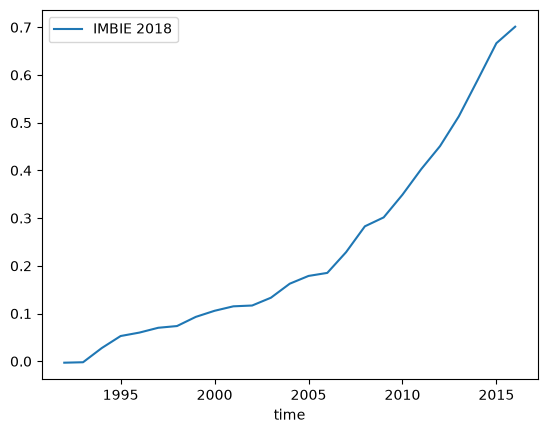

In [190]:
im18_df.plot()

## IMBIE 2021

In [192]:
im21_df = slc.ant_imbie(2021)
im21_df = im21_df.rename(columns={"Antarctica": "IMBIE 2021"})

<Axes: xlabel='time'>

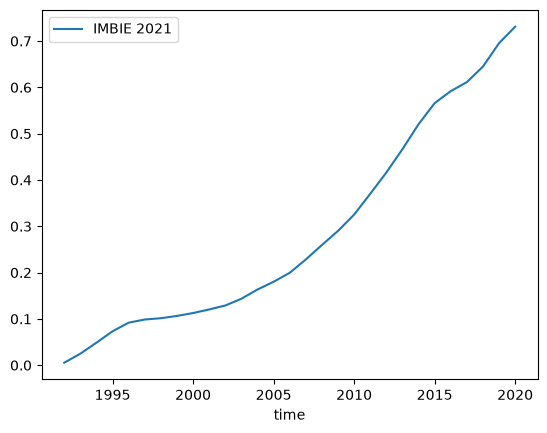

In [193]:
im21_df.plot()

## IMBIE 2026

In [195]:
im26_df = slc.ant_imbie(2026)
im26_df = im26_df.rename(columns={"Antarctica": "IMBIE 2026"})

<Axes: xlabel='time'>

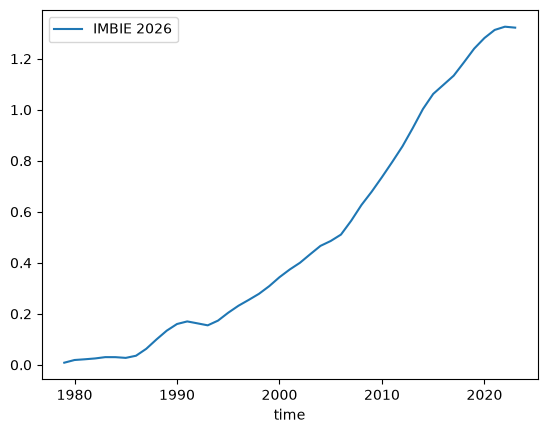

In [196]:
im26_df.plot()

## Rignot 2019

In [209]:
rig19_df = slc.ant_rignot19()
rig19_df = rig19_df.rename(columns={"Antarctica": "Rignot 2019"})

<Axes: xlabel='time'>

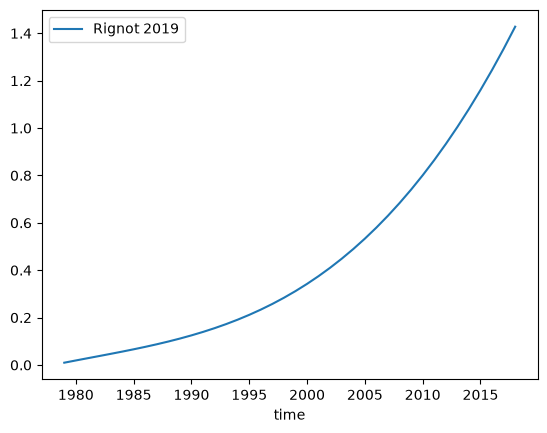

In [210]:
rig19_df.plot()

## Frederikse et al. 2020

In [211]:
fred20_df = slc.contrib_frederikse2020_glob("AIS")
fred20_df = fred20_df.rename(columns={"Antarctica":"Frederikse 2020"})

<Axes: xlabel='time'>

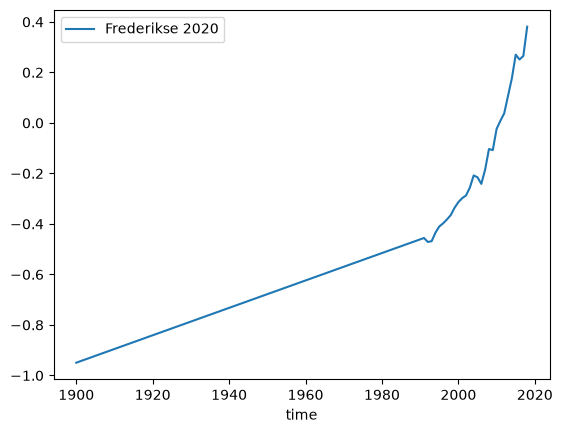

In [212]:
fred20_df.plot()

## Gravis

In [221]:
Gravis_dir = '../outputs/Gravis_Results/'
Gravis_ant_ds = xr.open_dataset(f'{Gravis_dir}Gravis_Antarctica.nc')

In [226]:
gravis_df = Gravis_ant_ds.Meanslr.squeeze().reset_coords(drop=True).to_dataframe(name='Gravis') 
gravis_df = gravis_df*1.1837950465122913 #for now corrected... 

In [233]:
gravis_df

,Gravis
time,
2002,0.000000
2003,0.025241
2004,0.057793
2005,0.065953
2006,0.041076
2007,0.090174
2008,0.169960
2009,0.164887
2010,0.222940


## Plot all time series together

In [246]:
#rig19_df.index = rig19_df.index.rename("Year_int").astype("int64")

combined_df = pd.concat([im18_df, im21_df, im26_df, rig19_df, fred20_df, gravis_df], axis=1, join="outer").sort_index()
combined_df.iloc[:,:-1] = combined_df.iloc[:,:-1] - combined_df.iloc[:,:-1].loc[1992:1996].mean()
ref = combined_df.loc[2014:2018,"Gravis"].mean() - combined_df.loc[2014:2018,"Frederikse 2020"].mean()
combined_df.loc[:,"Gravis"] = combined_df.loc[:,"Gravis"] - ref

In [247]:
combined_df

,IMBIE 2018,IMBIE 2021,IMBIE 2026,Rignot 2019,Frederikse 2020,Gravis
time,,,,,,
1900,NaN,NaN,NaN,NaN,-0.513049,NaN
1901,NaN,NaN,NaN,NaN,-0.507596,NaN
1902,NaN,NaN,NaN,NaN,-0.502124,NaN
1903,NaN,NaN,NaN,NaN,-0.496746,NaN
1904,NaN,NaN,NaN,NaN,-0.491327,NaN
...,...,...,...,...,...,...
2021,NaN,NaN,1.127529,NaN,NaN,0.920154
2022,NaN,NaN,1.140204,NaN,NaN,0.875371
2023,NaN,NaN,1.136474,NaN,NaN,0.863856


<Axes: xlabel='time', ylabel='Sea level contribution [cm]'>

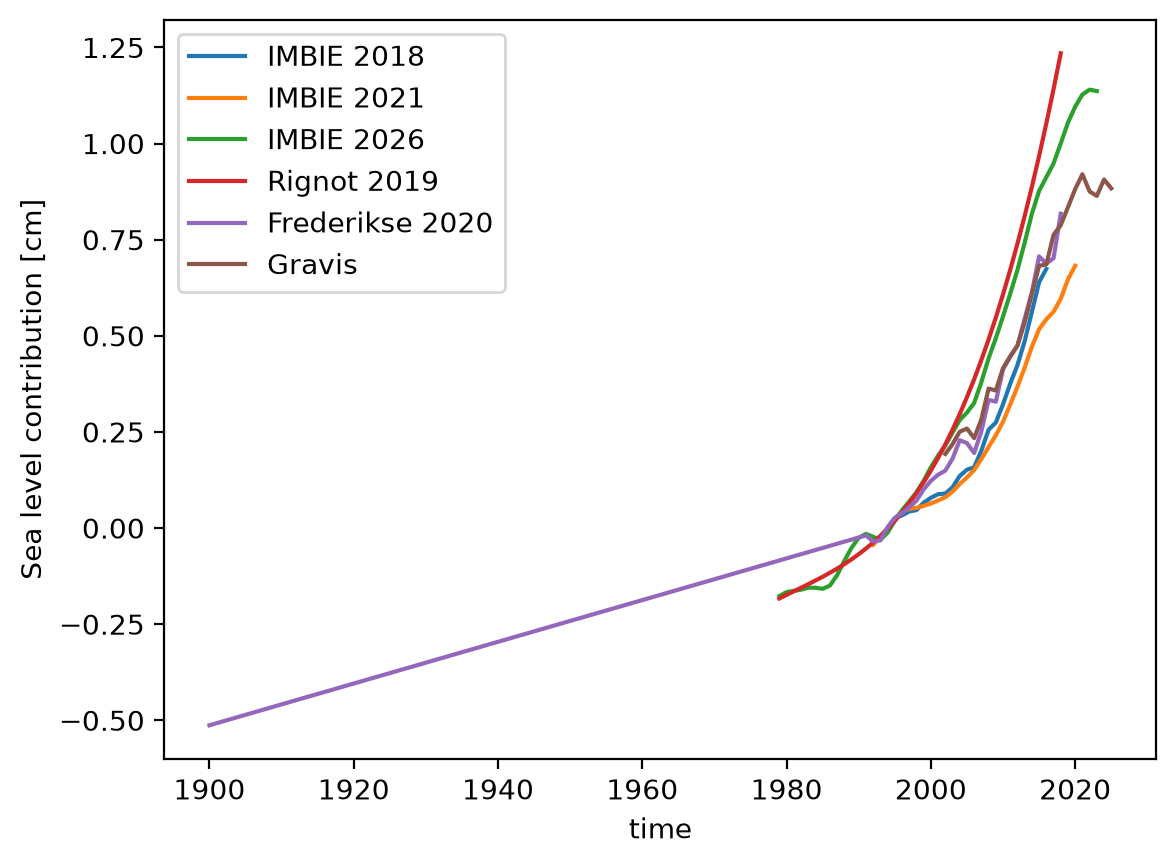

In [255]:
combined_df.plot(ylabel="Sea level contribution [cm]")

<Axes: xlabel='time', ylabel='Sea level contribution [cm]'>

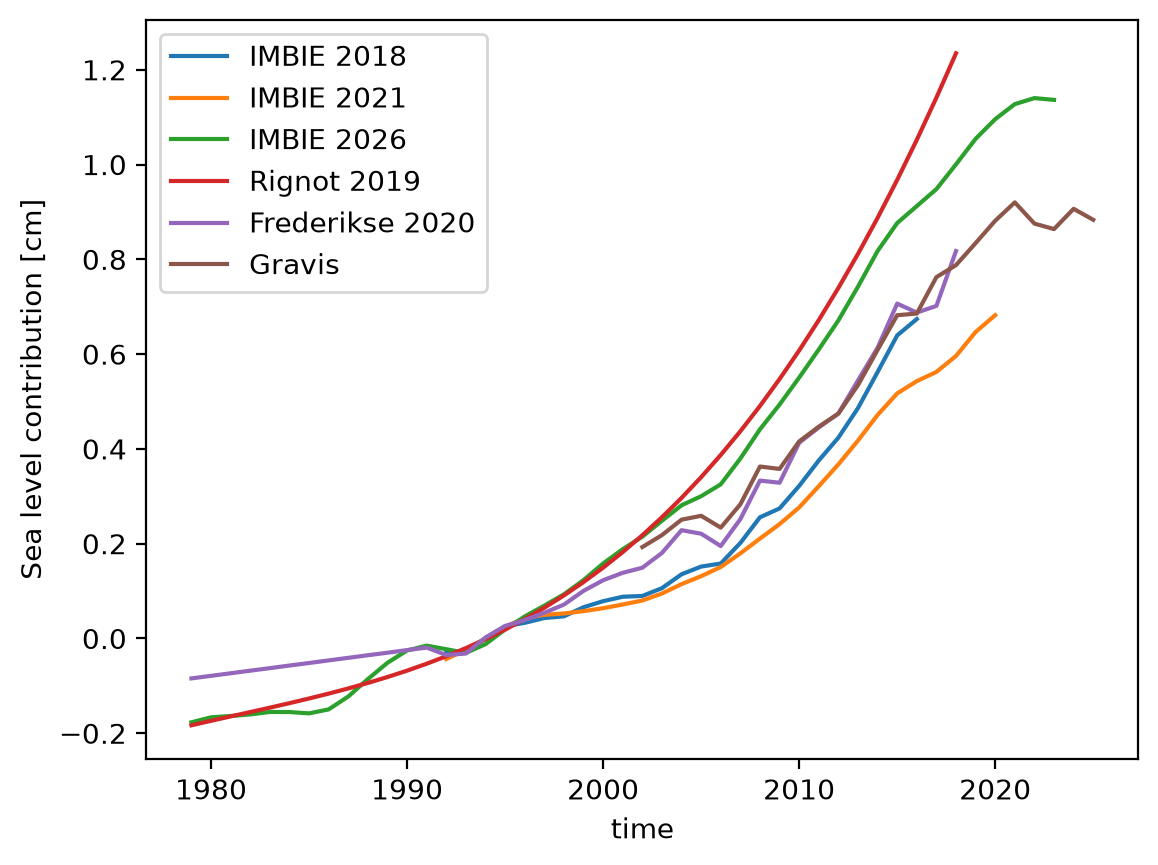

In [256]:
combined_df.loc[1979:].plot(ylabel="Sea level contribution [cm]")

In [148]:
# Previous code

In [104]:
# Mass balance from table 2 of Rignot et al. 2019
Time = np.arange(1979, 2018)
dM_79_89 = 40  #Gt/y
dM_89_99 = 49.6
dM_99_09 = 165.8 
dM_09_17 = 251.9
MB = np.zeros(len(Time))
MB[0:9] = dM_79_89
MB[9:19] = dM_89_99
MB[19:29] = dM_99_09
MB[29:len(Time)+1] = dM_09_17
MBcum = MB.cumsum()
SLR = MBcum / 360  # SLR in mm
SLR


array([  0.11111111,   0.22222222,   0.33333333,   0.44444444,
         0.55555556,   0.66666667,   0.77777778,   0.88888889,
         1.        ,   1.13777778,   1.27555556,   1.41333333,
         1.55111111,   1.68888889,   1.82666667,   1.96444444,
         2.10222222,   2.24      ,   2.37777778,   2.83833333,
         3.29888889,   3.75944444,   4.22      ,   4.68055556,
         5.14111111,   5.60166667,   6.06222222,   6.52277778,
         6.98333333,   7.68305556,   8.38277778,   9.0825    ,
         9.78222222,  10.48194444,  11.18166667,  11.88138889,
        12.58111111,  13.28083333,  13.98055556])

In [158]:
#Fit a second order polynomial and check that the total is ok
xy = np.array([1984, 1994, 2004, 2013])
dM = [dM_79_89, dM_89_99, dM_99_09, dM_09_17]

dM2f = np.polyfit(xy - xy[0], dM, 2)
xy2 = np.arange(1979,2019)

dM2 = dM2f[0] * (xy2 - xy[0])**2 + dM2f[1] * (xy2 - xy[0]) + dM2f[2]

slr_rig = dM2.cumsum() / 360
slr_rig_df = pd.DataFrame(data = dict(time= xy2, slr = slr_rig))
slr_rig_df = slr_rig_df.set_index('time')
slr_rig_df = slr_rig_df.reindex(np.arange(1950,2019)).fillna(0)
slr_rig_df

,slr
time,
1950,0.000000
1951,0.000000
1952,0.000000
1953,0.000000
1954,0.000000
1955,0.000000
1956,0.000000
1957,0.000000
1958,0.000000


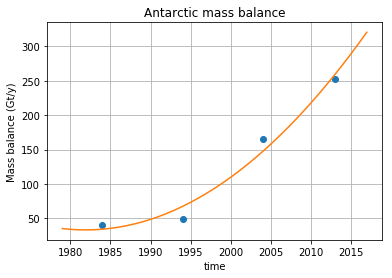

In [135]:
#Plot time series mass loss
fig, ax = plt.subplots() #figsize=(12,12)
ax.plot(xy, dM, 'o')
ax.plot(xy2, dM2, '-')
#ax.set_aspect(1)
plt.xlabel('time')
plt.ylabel('Mass balance (Gt/y)')
plt.title('Antarctic mass balance')
ax.grid(True)

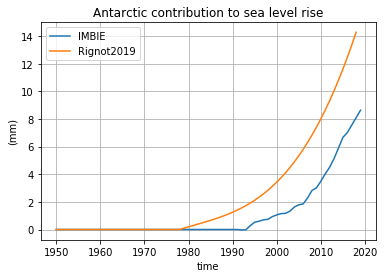

In [159]:
#Plot time series sea level rise
fig, ax = plt.subplots() #figsize=(12,12)
ax.plot(im_df, '-', label='IMBIE')
ax.plot(slr_rig_df , '-', label='Rignot2019')
#ax.set_aspect(1)
plt.xlabel('time')
plt.ylabel('(mm)')
plt.title('Antarctic contribution to sea level rise')
ax.grid(True)
plt.legend(loc='upper left')